## Install the packages

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sklearn

print("PipeGuard AI environment is ready!")

PipeGuard AI environment is ready!


## Data Understanding 

In [29]:

# Step 1: Load the main dataset

df = pd.read_csv("DATA/PipeGuard_Main_Dataset.csv.gz")

print("Dataset shape:", df.shape)

Dataset shape: (200448, 27)


In [30]:
df.head()

,pipe_id,assessment_date,pressure_zone,pipe_material,diameter_mm,pipe_length_m,installation_date,pipe_age_years,lining_material,burial_depth_m,...,max_pressure_bar_prev_12m,pressure_variation_bar_prev_12m,avg_flow_lps_prev_12m,rainfall_mm_prev_12m,frost_days_prev_12m,previous_break_count,years_since_last_break,inspections_prev_3y,years_since_last_inspection,failure_next_12_months
0,10080,2009-01-01,KIT 6,DI,450,34.21,1979-01-01,30,NONE,1.67,...,5.549,0.152,9.465,997.4,93,0,NaN,1,3,0
1,76299,2009-01-01,KIT 4,DI,300,0.36,1968-07-01,41,NONE,1.18,...,6.288,0.376,5.114,921.4,70,0,NaN,1,4,0
2,10110,2009-01-01,KIT 6,DI,450,67.85,1979-01-01,30,NONE,2.46,...,6.138,0.266,9.358,945.1,73,0,NaN,2,4,0
3,82566,2009-01-01,KIT 6,DI,450,7.04,1979-01-01,30,NONE,1.65,...,6.239,0.318,7.661,732.5,71,0,NaN,1,3,0
4,82568,2009-01-01,KIT 6,DI,450,14.96,1979-01-01,30,NONE,1.75,...,6.088,0.362,7.891,1000.0,66,0,NaN,0,2,0


In [31]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200448 entries, 0 to 200447
Data columns (total 27 columns):
 #   Column                           Non-Null Count   Dtype  
---  ------                           --------------   -----  
 0   pipe_id                          200448 non-null  int64  
 1   assessment_date                  200448 non-null  str    
 2   pressure_zone                    200448 non-null  str    
 3   pipe_material                    200448 non-null  str    
 4   diameter_mm                      200448 non-null  int64  
 5   pipe_length_m                    200448 non-null  float64
 6   installation_date                198590 non-null  str    
 7   pipe_age_years                   200448 non-null  int64  
 8   lining_material                  200448 non-null  str    
 9   burial_depth_m                   200448 non-null  float64
 10  soil_type                        200448 non-null  str    
 11  soil_corrosivity_index           197682 non-null  float64
 12  traffic_load_

In [32]:
df.describe()

,pipe_id,diameter_mm,pipe_length_m,pipe_age_years,burial_depth_m,soil_corrosivity_index,traffic_load_index,condition_score,criticality_rating,customers_served,...,max_pressure_bar_prev_12m,pressure_variation_bar_prev_12m,avg_flow_lps_prev_12m,rainfall_mm_prev_12m,frost_days_prev_12m,previous_break_count,years_since_last_break,inspections_prev_3y,years_since_last_inspection,failure_next_12_months
count,200448.000000,200448.000000,200448.000000,200448.000000,200448.000000,197682.000000,200448.000000,196279.000000,200448.000000,200448.000000,...,200448.000000,200448.000000,198086.000000,200448.000000,200448.000000,200448.000000,8162.000000,200448.000000,200448.000000,200448.000000
mean,76015.442549,231.109066,61.361530,29.962524,1.672829,4.455310,37.483541,7.767379,5.230583,8.013131,...,7.192727,0.341339,3.296598,888.925007,84.115451,0.043767,5.544964,0.739618,1.745296,0.006101
std,33834.814179,111.619303,85.254648,20.404177,0.290316,2.016387,18.745060,1.136253,2.480681,7.434001,...,25.255641,0.103307,3.187703,78.997624,11.536321,0.220378,3.745127,0.640599,1.408981,0.077873
min,270.000000,50.000000,-573.890000,1.000000,-2.260000,0.080000,0.300000,2.740000,-1.000000,1.000000,...,3.767000,0.040000,0.150000,502.300000,35.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,61903.000000,150.000000,7.050000,12.000000,1.490000,2.900000,22.700000,7.000000,5.000000,3.000000,...,5.815000,0.270000,1.465000,836.100000,76.000000,0.000000,2.000000,0.000000,0.000000,0.000000
50%,83994.000000,200.000000,16.680000,27.000000,1.680000,4.360000,36.000000,7.900000,6.000000,6.000000,...,6.150000,0.340000,2.158000,888.900000,84.000000,0.000000,5.000000,1.000000,2.000000,0.000000
75%,91872.000000,300.000000,93.420000,45.000000,1.860000,5.940000,50.700000,8.650000,7.000000,10.000000,...,6.482000,0.411000,4.332000,941.900000,92.000000,0.000000,8.000000,1.000000,3.000000,0.000000
max,159294.000000,1200.000000,1998.430000,136.000000,2.800000,9.810000,97.800000,10.000000,10.000000,95.000000,...,739.870000,0.766000,38.000000,1300.000000,135.000000,5.000000,16.000000,3.000000,5.000000,1.000000


## Identify Missing Values

In [33]:
df.isna().sum()

pipe_id                                 0
assessment_date                         0
pressure_zone                           0
pipe_material                           0
diameter_mm                             0
pipe_length_m                           0
installation_date                    1858
pipe_age_years                          0
lining_material                         0
burial_depth_m                          0
soil_type                               0
soil_corrosivity_index               2766
traffic_load_index                      0
condition_score                      4169
criticality_rating                      0
customers_served                        0
avg_pressure_bar_prev_12m            5780
max_pressure_bar_prev_12m               0
pressure_variation_bar_prev_12m         0
avg_flow_lps_prev_12m                2362
rainfall_mm_prev_12m                    0
frost_days_prev_12m                     0
previous_break_count                    0
years_since_last_break            

In [34]:
# Count exact duplicate records
duplicate_count = df.duplicated().sum()

print("Total records:", len(df))
print("Exact duplicate records:", duplicate_count)

Total records: 200448
Exact duplicate records: 305


In [35]:
# Check repeated pipeline assessments
duplicate_assessments = df.duplicated(
    subset=["pipe_id", "assessment_date"]
).sum()

print("Repeated pipe-date combinations:", duplicate_assessments)

Repeated pipe-date combinations: 305


## Target Variable Distribution

In [36]:
# Examine the distribution of our prediction target

print(df["failure_next_12_months"].value_counts())

print("\nPercentage distribution:")
print(
    df["failure_next_12_months"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

failure_next_12_months
0    199225
1      1223
Name: count, dtype: int64

Percentage distribution:
failure_next_12_months
0    99.39
1     0.61
Name: proportion, dtype: float64


In [37]:
# Inspect unique values and frequencies in pipe material

print(df["pipe_material"].value_counts(dropna=False))

pipe_material
PVC             83164
DI              75315
CI              30168
PVCO             4873
CPP              3226
AC                851
HDPE              655
PVC pipe          262
ductile iron      254
 PVC              251
 D.I.             248
pvc               244
Ductile Iron      239
PVCB              175
COP               118
cast iron          99
Cast Iron          90
 C.I.              79
ST                 77
PVCF               46
HDPE IN CI         14
Name: count, dtype: int64


## Data Preparation

In [38]:
# Create a working copy and remove exact duplicates
df_clean = df.drop_duplicates().copy()

# Compare the number of records
print("Original records:", len(df))
print("Cleaned records:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))

# Verify that no exact duplicates remain
print("Remaining duplicates:", df_clean.duplicated().sum())

Original records: 200448
Cleaned records: 200143
Duplicates removed: 305
Remaining duplicates: 0


In [39]:
#Missing values after duplicate removal

missing_after_duplicates = df_clean.isna().sum()

print(missing_after_duplicates[missing_after_duplicates > 0])

installation_date              1858
soil_corrosivity_index         2764
condition_score                4165
avg_pressure_bar_prev_12m      5767
avg_flow_lps_prev_12m          2358
years_since_last_break       191992
dtype: int64


In [40]:
# Investigate missing break history

# Find columns related to pipeline breaks or failures
break_columns = [
    col for col in df_clean.columns
    if "break" in col.lower() or "failure" in col.lower()
]

print("Break-related columns:")
print(break_columns)

# Preview the values
display(df_clean[break_columns].head(10))

Break-related columns:
['previous_break_count', 'years_since_last_break', 'failure_next_12_months']


,previous_break_count,years_since_last_break,failure_next_12_months
0,0,NaN,0
1,0,NaN,0
2,0,NaN,0
3,0,NaN,0
4,0,NaN,0
5,0,NaN,0
6,0,NaN,0
7,0,NaN,0
8,0,NaN,0
9,0,NaN,0


In [41]:
# Check missing break history against previous break count

print("Missing years with zero previous breaks:")
print(
    df_clean.loc[
        df_clean["previous_break_count"] == 0,
        "years_since_last_break"
    ].isna().sum()
)

print("\nMissing years despite previous breaks:")
print(
    df_clean.loc[
        df_clean["previous_break_count"] > 0,
        "years_since_last_break"
    ].isna().sum()
)

print("\nRecorded years despite zero previous breaks:")
print(
    df_clean.loc[
        df_clean["previous_break_count"] == 0,
        "years_since_last_break"
    ].notna().sum()
)

Missing years with zero previous breaks:
191992

Missing years despite previous breaks:
0

Recorded years despite zero previous breaks:
0


In [42]:
# Create a feature indicating previous break history

df_clean["has_previous_break"] = (
    df_clean["previous_break_count"] > 0
).astype(int)

print(df_clean["has_previous_break"].value_counts())

has_previous_break
0    191992
1      8151
Name: count, dtype: int64


## Identify Invalid Numerical Values

In [43]:
# Identify physically invalid pipeline measurements

invalid_values = {
    "Negative pipe length": (df_clean["pipe_length_m"] < 0).sum(),
    "Negative burial depth": (df_clean["burial_depth_m"] < 0).sum(),
    "Negative pipe age": (df_clean["pipe_age_years"] < 0).sum(),
    "Invalid pipe diameter": (df_clean["diameter_mm"] <= 0).sum()
}

for issue, count in invalid_values.items():
    print(f"{issue}: {count}")

Negative pipe length: 226
Negative burial depth: 134
Negative pipe age: 0
Invalid pipe diameter: 0


In [44]:
# Replace physically impossible measurements with missing values

df_clean.loc[
    df_clean["pipe_length_m"] < 0,
    "pipe_length_m"
] = np.nan

df_clean.loc[
    df_clean["burial_depth_m"] < 0,
    "burial_depth_m"
] = np.nan

# Verify the corrections
print("Remaining negative pipe lengths:",
      (df_clean["pipe_length_m"] < 0).sum())

print("Remaining negative burial depths:",
      (df_clean["burial_depth_m"] < 0).sum())

print("\nMissing pipe lengths:",
      df_clean["pipe_length_m"].isna().sum())

print("Missing burial depths:",
      df_clean["burial_depth_m"].isna().sum())

print("\nDataset shape:", df_clean.shape)

Remaining negative pipe lengths: 0
Remaining negative burial depths: 0

Missing pipe lengths: 226
Missing burial depths: 134

Dataset shape: (200143, 28)


## Standardize Pipe Material Categories

In [45]:

original_material = df_clean["pipe_material"].copy()

# Standardize capitalization and remove extra spaces
df_clean["pipe_material"] = (
    df_clean["pipe_material"]
    .str.strip()
    .str.upper()
)

# Replace different names for the same material
material_mapping = {
    "PVC PIPE": "PVC",
    "DUCTILE IRON": "DI",
    "D.I.": "DI",
    "CAST IRON": "CI",
    "C.I.": "CI"
}

df_clean["pipe_material"] = (
    df_clean["pipe_material"].replace(material_mapping)
)

# Verify the changes
print("Records standardized:",
      (original_material != df_clean["pipe_material"]).sum())

print("\nStandardized material categories:")
print(df_clean["pipe_material"].value_counts())

print("\nDataset shape:", df_clean.shape)

Records standardized: 1766

Standardized material categories:
pipe_material
PVC           83794
DI            75938
CI            30394
PVCO           4865
CPP            3219
AC              849
HDPE            654
PVCB            175
COP             118
ST               77
PVCF             46
HDPE IN CI       14
Name: count, dtype: int64

Dataset shape: (200143, 28)


## Exploratory Data Analysis (EDA)


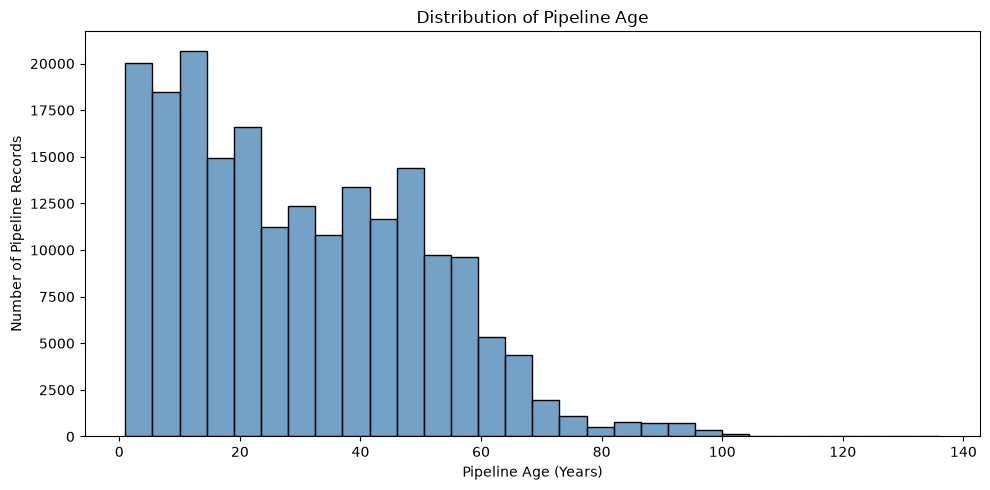

In [46]:
# EDA 1 — Visualize pipeline age distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x="pipe_age_years",
    bins=30,
    color="steelblue"
)

plt.title("Distribution of Pipeline Age")
plt.xlabel("Pipeline Age (Years)")
plt.ylabel("Number of Pipeline Records")

plt.tight_layout()
plt.show()

In [47]:
#Pipeline Age vs. Failure Rate

# Create age groups
df_eda = df_clean.copy()

df_eda["age_group"] = pd.cut(
    df_eda["pipe_age_years"],
    bins=[0, 10, 20, 30, 40, 50, 60, 80, 100, 140],
    right=False
)

# Calculate the failure rate for each age group
age_failure = (
    df_eda.groupby("age_group", observed=True)
    ["failure_next_12_months"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

# Rename columns
age_failure.columns = [
    "Age Group",
    "Total Records",
    "Failures",
    "Failure Rate"
]

# Convert failure rate into percentage
age_failure["Failure Rate (%)"] = (
    age_failure["Failure Rate"] * 100
)

display(age_failure)

,Age Group,Total Records,Failures,Failure Rate,Failure Rate (%)
0,"[0, 10)",38531,77,0.001998,0.199839
1,"[10, 20)",39241,82,0.002090,0.208965
2,"[20, 30)",29193,95,0.003254,0.325420
3,"[30, 40)",26273,152,0.005785,0.578541
4,"[40, 50)",28691,223,0.007772,0.777247
5,"[50, 60)",22055,240,0.010882,1.088189
6,"[60, 80)",13029,242,0.018574,1.857395
7,"[80, 100)",2807,96,0.034200,3.420021
8,"[100, 140)",323,15,0.046440,4.643963


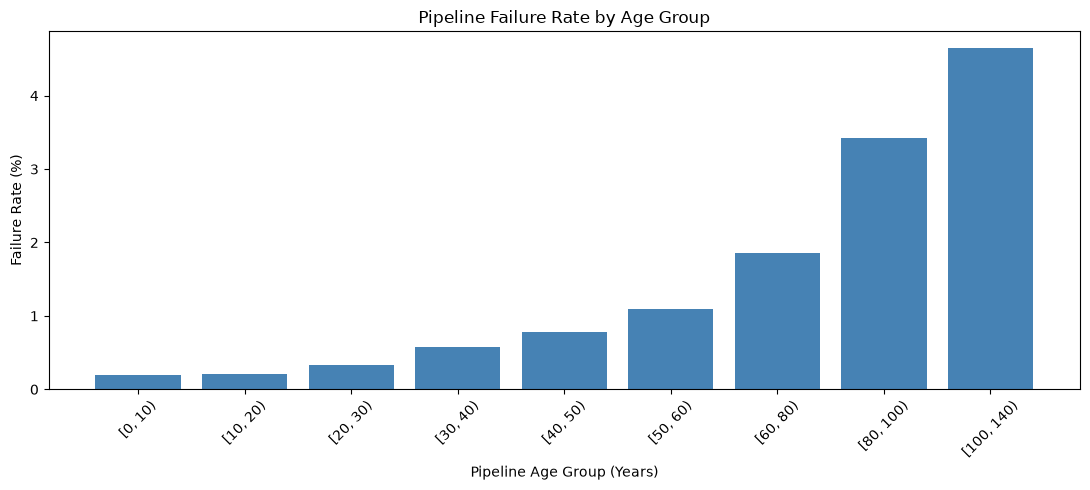

In [48]:
# Visualize failure rates by pipeline age group

plt.figure(figsize=(11, 5))

plt.bar(
    age_failure["Age Group"].astype(str),
    age_failure["Failure Rate (%)"],
    color="steelblue"
)

plt.title("Pipeline Failure Rate by Age Group")
plt.xlabel("Pipeline Age Group (Years)")
plt.ylabel("Failure Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Pipe Material vs. Failure Rate

In [49]:
# EDA 3 — Calculate failure rates by pipe material

material_failure = (
    df_clean.groupby("pipe_material")["failure_next_12_months"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

material_failure.columns = [
    "Pipe Material",
    "Total Records",
    "Failures",
    "Failure Rate"
]

material_failure["Failure Rate (%)"] = (
    material_failure["Failure Rate"] * 100
)

material_failure = material_failure.sort_values(
    "Failure Rate (%)",
    ascending=False
)

display(material_failure)

,Pipe Material,Total Records,Failures,Failure Rate,Failure Rate (%)
1,CI,30394,543,0.017865,1.786537
2,COP,118,2,0.016949,1.694915
0,AC,849,6,0.007067,0.706714
4,DI,75938,469,0.006176,0.617609
3,CPP,3219,18,0.005592,0.559180
5,HDPE,654,3,0.004587,0.458716
10,PVCO,4865,13,0.002672,0.267215
7,PVC,83794,168,0.002005,0.200492
6,HDPE IN CI,14,0,0.000000,0.000000
8,PVCB,175,0,0.000000,0.000000


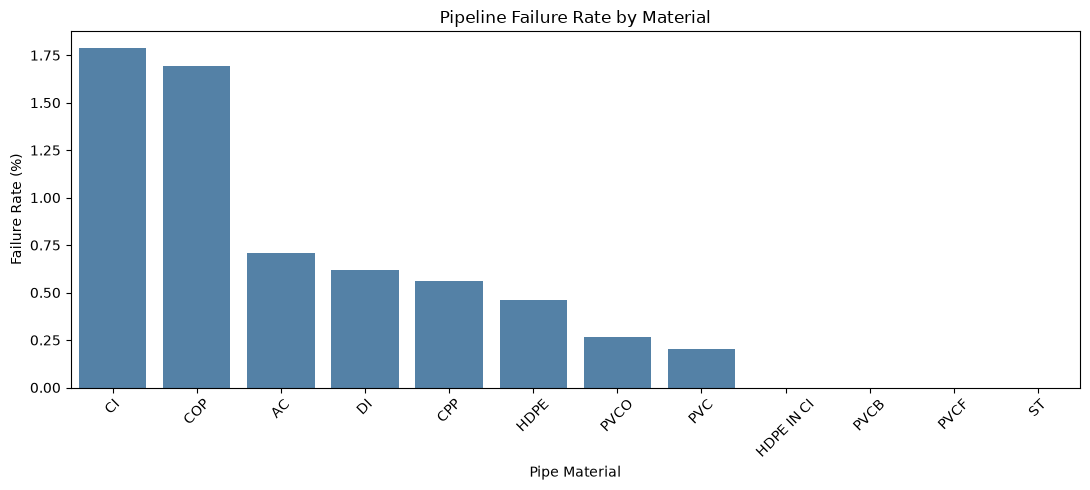

In [50]:
# Visualize failure rates by pipe material

plt.figure(figsize=(11, 5))

sns.barplot(
    data=material_failure,
    x="Pipe Material",
    y="Failure Rate (%)",
    color="steelblue"
)

plt.title("Pipeline Failure Rate by Material")
plt.xlabel("Pipe Material")
plt.ylabel("Failure Rate (%)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Machine Learning Data Preparation

In [51]:
# Create a separate working dataset for model preparation
df_model = df_clean.copy()

# Display all available columns and their data types
feature_info = pd.DataFrame({
    "Column": df_model.columns,
    "Data Type": df_model.dtypes.astype(str),
    "Missing Values": df_model.isna().sum()
})

display(feature_info.reset_index(drop=True))

print("Dataset shape:", df_model.shape)

,Column,Data Type,Missing Values
0,pipe_id,int64,0
1,assessment_date,str,0
2,pressure_zone,str,0
3,pipe_material,str,0
4,diameter_mm,int64,0
5,pipe_length_m,float64,226
6,installation_date,str,1858
7,pipe_age_years,int64,0
8,lining_material,str,0
9,burial_depth_m,float64,134


Dataset shape: (200143, 28)


In [52]:
#Check Assessment Dates and Pipeline IDs

# Convert assessment dates to datetime
df_model["assessment_date"] = pd.to_datetime(
    df_model["assessment_date"],
    errors="coerce"
)

# Check the assessment period
print("Earliest assessment:", df_model["assessment_date"].min())
print("Latest assessment:", df_model["assessment_date"].max())
print("Invalid dates:", df_model["assessment_date"].isna().sum())

# Check unique and repeated pipelines
print("\nTotal records:", len(df_model))
print("Unique pipelines:", df_model["pipe_id"].nunique())
print("Repeated pipeline IDs:", df_model.duplicated("pipe_id").sum())

# Examine records and failures by assessment year
yearly_summary = (
    df_model.groupby(df_model["assessment_date"].dt.year)
    ["failure_next_12_months"]
    .agg(["size", "sum"])
)

yearly_summary.columns = ["Total Records", "Failures"]

display(yearly_summary)

Earliest assessment: 2009-01-01 00:00:00
Latest assessment: 2025-01-01 00:00:00
Invalid dates: 0

Total records: 200143
Unique pipelines: 15943
Repeated pipeline IDs: 184200


,Total Records,Failures
assessment_date,,
2009,9688,61
2010,9872,61
2011,10024,66
2012,10271,52
2013,10560,67
2014,10737,58
2015,10986,63
2016,11366,80
2017,11588,75


## Verify Temporal Integrity and Label Availability

In [53]:
# Verify the temporal structure before data splitting

target = "failure_next_12_months"

# Check label completeness and valid target values
print("Missing target labels:", df_model[target].isna().sum())
print("Target values:", sorted(df_model[target].dropna().unique()))

# Check whether all assessments occur on January 1
all_january_first = (
    (df_model["assessment_date"].dt.month == 1) &
    (df_model["assessment_date"].dt.day == 1)
).all()

print("All assessments on January 1:", all_january_first)

# Summarize the periods used for model evaluation
period_summary = (
    df_model.assign(
        year=df_model["assessment_date"].dt.year
    )
    .groupby("year")
    .agg(
        records=(target, "size"),
        available_labels=(target, "count"),
        failures=(target, "sum"),
        first_assessment=("assessment_date", "min"),
        last_assessment=("assessment_date", "max")
    )
)

display(period_summary.loc[[2023, 2024, 2025]])

# Check whether the 12-month outcome windows overlap
train_outcome_end = (
    period_summary.loc[2023, "last_assessment"]
    + pd.DateOffset(years=1)
)

val_start = period_summary.loc[2024, "first_assessment"]

val_outcome_end = (
    period_summary.loc[2024, "last_assessment"]
    + pd.DateOffset(years=1)
)

test_start = period_summary.loc[2025, "first_assessment"]

test_outcome_end = (
    period_summary.loc[2025, "last_assessment"]
    + pd.DateOffset(years=1)
)

print("\nTraining outcomes end by validation start:",
      train_outcome_end <= val_start)

print("Validation outcomes end by testing start:",
      val_outcome_end <= test_start)

print("2025 outcome window has elapsed:",
      test_outcome_end <= pd.Timestamp.today())

Missing target labels: 0
Target values: [np.int64(0), np.int64(1)]
All assessments on January 1: True


,records,available_labels,failures,first_assessment,last_assessment
year,,,,,
2023,13742,13742,87,2023-01-01,2023-01-01
2024,14055,14055,88,2024-01-01,2024-01-01
2025,14209,14209,93,2025-01-01,2025-01-01



Training outcomes end by validation start: True
Validation outcomes end by testing start: True
2025 outcome window has elapsed: True


 ## Train/Validation/Test Split

In [54]:
# Split the dataset chronologically

train_df = df_model[
    df_model["assessment_date"].dt.year <= 2023
].copy()

val_df = df_model[
    df_model["assessment_date"].dt.year == 2024
].copy()

test_df = df_model[
    df_model["assessment_date"].dt.year == 2025
].copy()

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

Training: (171879, 28)
Validation: (14055, 28)
Testing: (14209, 28)


In [55]:
# Separate Features (X) and Target (y)
# Define the target variable
target = "failure_next_12_months"

# Exclude columns not used as prediction features
exclude_columns = [
    target,
    "pipe_id",
    "assessment_date",
    "installation_date",
    "criticality_rating",
    "customers_served"
]

# Separate features (X) and target (y)

# Training data
X_train = train_df.drop(columns=exclude_columns)
y_train = train_df[target]

# Validation data
X_val = val_df.drop(columns=exclude_columns)
y_val = val_df[target]

# Testing data
X_test = test_df.drop(columns=exclude_columns)
y_test = test_df[target]

# Verify the results
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_val:", X_val.shape)
print("y_val:", y_val.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nSelected features:")
print(X_train.columns.tolist())

X_train: (171879, 22)
y_train: (171879,)

X_val: (14055, 22)
y_val: (14055,)

X_test: (14209, 22)
y_test: (14209,)

Selected features:
['pressure_zone', 'pipe_material', 'diameter_mm', 'pipe_length_m', 'pipe_age_years', 'lining_material', 'burial_depth_m', 'soil_type', 'soil_corrosivity_index', 'traffic_load_index', 'condition_score', 'avg_pressure_bar_prev_12m', 'max_pressure_bar_prev_12m', 'pressure_variation_bar_prev_12m', 'avg_flow_lps_prev_12m', 'rainfall_mm_prev_12m', 'frost_days_prev_12m', 'previous_break_count', 'years_since_last_break', 'inspections_prev_3y', 'years_since_last_inspection', 'has_previous_break']


## Build the Preprocessing Pipeline

In [56]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Identify categorical features
categorical_features = [
    "pressure_zone",
    "pipe_material",
    "lining_material",
    "soil_type"
]

# Identify the special historical feature
break_recency_feature = ["years_since_last_break"]

# Identify the remaining numerical features
numerical_features = [
    col for col in X_train.columns
    if col not in categorical_features + break_recency_feature
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Break recency features:", len(break_recency_feature))

Numerical features: 17
Categorical features: 4
Break recency features: 1


In [57]:
# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Special treatment for previous break recency
break_recency_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value=-1
    )),
    ("scaler", StandardScaler())
])

# Combine all preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
        ("break_recency", break_recency_pipeline,
         break_recency_feature)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [58]:
# Numerical preprocessing
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Historical break-recency preprocessing
break_recency_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value=-1
    )),
    ("scaler", StandardScaler())
])

# Combine preprocessing steps
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features),
        ("break_recency", break_recency_pipeline,
         break_recency_feature)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


# Model Training

## Logistic Regression

In [59]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Combine preprocessing with Logistic Regression
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train the model using training data only
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


## Logistic Regression — Validation Metrics

In [60]:
# Import evaluation metrics
import numpy as np

from sklearn.metrics import (
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Generate predicted probabilities
y_val_prob = logistic_model.predict_proba(X_val)[:, 1]

# Convert probabilities into predicted classes
y_val_pred = (y_val_prob >= 0.5).astype(int)

# Calculate classification metrics
ap = average_precision_score(y_val, y_val_prob)
precision = precision_score(y_val, y_val_pred, zero_division=0)
recall = recall_score(y_val, y_val_pred, zero_division=0)
f1 = f1_score(y_val, y_val_pred, zero_division=0)

# Calculate the baseline failure rate
baseline = y_val.mean()

# Display results
print("Logistic Regression — Validation Results")
print("----------------------------------------")
print(f"Average Precision (AP): {ap:.4f}")
print(f"Baseline AP:            {baseline:.4f}")
print(f"Precision:              {precision:.4f}")
print(f"Recall:                 {recall:.4f}")
print(f"F1 Score:               {f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Logistic Regression — Validation Results
----------------------------------------
Average Precision (AP): 0.0290
Baseline AP:            0.0063
Precision:              0.0148
Recall:                 0.7614
F1 Score:               0.0290

Confusion Matrix:
[[9506 4461]
 [  21   67]]


In [61]:
#Top 5% Risk Prioritization
#Evaluate the top 5% highest-risk pipelines

# Number of records to prioritize
top_n = int(np.ceil(len(y_val_prob) * 0.05))

# Identify the highest predicted risk scores
top_indices = np.argsort(y_val_prob)[-top_n:]

# Convert the actual outcomes to a NumPy array
actual_failures = y_val.to_numpy()

# Count failures captured in the top 5%
failures_top5 = actual_failures[top_indices].sum()
total_failures = actual_failures.sum()

# Calculate prioritization metrics
top5_precision = failures_top5 / top_n
top5_capture = failures_top5 / total_failures
lift = top5_precision / y_val.mean()

print("Top 5% Risk Prioritization")
print("--------------------------")
print("Records selected:", top_n)
print("Failures captured:", failures_top5)
print("Total failures:", total_failures)
print(f"Top 5% precision: {top5_precision:.2%}")
print(f"Failure capture rate: {top5_capture:.2%}")
print(f"Lift over baseline: {lift:.2f}x")

Top 5% Risk Prioritization
--------------------------
Records selected: 703
Failures captured: 22
Total failures: 88
Top 5% precision: 3.13%
Failure capture rate: 25.00%
Lift over baseline: 5.00x


## Logistic Regression — Classification Report

In [62]:
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# Predict using the 2024 validation data
y_val_pred = logistic_model.predict(X_val)

# Evaluate the model
print("Accuracy:", accuracy_score(y_val, y_val_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

print("\nClassification Report:")
print(classification_report(y_val, y_val_pred))

Accuracy: 0.6811099252934899

Confusion Matrix:
[[9506 4461]
 [  21   67]]

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.68      0.81     13967
           1       0.01      0.76      0.03        88

    accuracy                           0.68     14055
   macro avg       0.51      0.72      0.42     14055
weighted avg       0.99      0.68      0.80     14055



## Random Forest Classification

In [63]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Create the Random Forest model
rf_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", RandomForestClassifier(
        n_estimators=150,
        max_depth=16,
        min_samples_leaf=10,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    ))
])

# Train using historical training data only
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


## Random Forest Validation

### Classification Metrics and Report

In [64]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Predict using 2024 validation data
rf_val_prob = rf_model.predict_proba(X_val)[:, 1]
rf_val_pred = rf_model.predict(X_val)

# Calculate evaluation metrics
rf_accuracy = accuracy_score(y_val, rf_val_pred)
rf_ap = average_precision_score(y_val, rf_val_prob)
rf_precision = precision_score(y_val, rf_val_pred, zero_division=0)
rf_recall = recall_score(y_val, rf_val_pred, zero_division=0)
rf_f1 = f1_score(y_val, rf_val_pred, zero_division=0)

# Display results
print("Random Forest — Validation Results")
print("----------------------------------")
print(f"Accuracy:          {rf_accuracy:.4f}")
print(f"Average Precision: {rf_ap:.4f}")
print(f"Baseline AP:       {y_val.mean():.4f}")
print(f"Precision:         {rf_precision:.4f}")
print(f"Recall:            {rf_recall:.4f}")
print(f"F1 Score:          {rf_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    rf_val_pred,
    digits=4,
    zero_division=0
))

Random Forest — Validation Results
----------------------------------
Accuracy:          0.9688
Average Precision: 0.0208
Baseline AP:       0.0063
Precision:         0.0346
Recall:            0.1477
F1 Score:          0.0560

Confusion Matrix:
[[13604   363]
 [   75    13]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9945    0.9740    0.9842     13967
           1     0.0346    0.1477    0.0560        88

    accuracy                         0.9688     14055
   macro avg     0.5145    0.5609    0.5201     14055
weighted avg     0.9885    0.9688    0.9783     14055



In [65]:
## Top 5% Risk Prioritization — Random Forest
# Evaluate the top 5% highest-risk records

top_n = int(np.ceil(len(rf_val_prob) * 0.05))

# Select highest-risk record positions
rf_top_indices = np.argsort(rf_val_prob)[-top_n:]

# Count captured failures
actual_failures = y_val.to_numpy()

rf_failures_top5 = actual_failures[rf_top_indices].sum()
total_failures = actual_failures.sum()

# Calculate business metrics
rf_top5_precision = rf_failures_top5 / top_n
rf_top5_capture = rf_failures_top5 / total_failures
rf_lift = rf_top5_precision / y_val.mean()

print("Random Forest — Top 5% Prioritization")
print("-------------------------------------")
print("Records selected:", top_n)
print("Failures captured:", rf_failures_top5)
print("Total failures:", total_failures)
print(f"Top 5% precision: {rf_top5_precision:.2%}")
print(f"Failure capture rate: {rf_top5_capture:.2%}")
print(f"Lift over baseline: {rf_lift:.2f}x")

Random Forest — Top 5% Prioritization
-------------------------------------
Records selected: 703
Failures captured: 19
Total failures: 88
Top 5% precision: 2.70%
Failure capture rate: 21.59%
Lift over baseline: 4.32x


## Gradient Boosting Classification

In [66]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.base import clone
from sklearn.pipeline import Pipeline

# Create the Gradient Boosting model
gb_model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.05,
        max_depth=3,
        subsample=0.8,
        random_state=42
    ))
])

# Train using training data only
gb_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


## Gradient Boosting Validation

### Classification Metrics and Report

In [67]:
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Generate predictions using 2024 validation data
gb_val_prob = gb_model.predict_proba(X_val)[:, 1]
gb_val_pred = gb_model.predict(X_val)

# Calculate evaluation metrics
gb_accuracy = accuracy_score(y_val, gb_val_pred)
gb_ap = average_precision_score(y_val, gb_val_prob)
gb_precision = precision_score(y_val, gb_val_pred, zero_division=0)
gb_recall = recall_score(y_val, gb_val_pred, zero_division=0)
gb_f1 = f1_score(y_val, gb_val_pred, zero_division=0)

# Display results
print("Gradient Boosting — Validation Results")
print("--------------------------------------")
print(f"Accuracy:          {gb_accuracy:.4f}")
print(f"Average Precision: {gb_ap:.4f}")
print(f"Baseline AP:       {y_val.mean():.4f}")
print(f"Precision:         {gb_precision:.4f}")
print(f"Recall:            {gb_recall:.4f}")
print(f"F1 Score:          {gb_f1:.4f}")

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, gb_val_pred))

print("\nClassification Report:")
print(classification_report(
    y_val,
    gb_val_pred,
    digits=4,
    zero_division=0
))

Gradient Boosting — Validation Results
--------------------------------------
Accuracy:          0.9935
Average Precision: 0.0324
Baseline AP:       0.0063
Precision:         0.0000
Recall:            0.0000
F1 Score:          0.0000

Confusion Matrix:
[[13964     3]
 [   88     0]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9937    0.9998    0.9968     13967
           1     0.0000    0.0000    0.0000        88

    accuracy                         0.9935     14055
   macro avg     0.4969    0.4999    0.4984     14055
weighted avg     0.9875    0.9935    0.9905     14055



## Top 5% Risk Prioritization — Gradient Boosting

In [68]:
# Evaluate the top 5% highest-risk records

top_n = int(np.ceil(len(gb_val_prob) * 0.05))

# Select highest-risk record positions
gb_top_indices = np.argsort(gb_val_prob)[-top_n:]

# Count actual simulated failures
actual_failures = y_val.to_numpy()

gb_failures_top5 = actual_failures[gb_top_indices].sum()
total_failures = actual_failures.sum()

# Calculate business evaluation metrics
gb_top5_precision = gb_failures_top5 / top_n
gb_top5_capture = gb_failures_top5 / total_failures
gb_lift = gb_top5_precision / y_val.mean()

print("Gradient Boosting — Top 5% Prioritization")
print("-----------------------------------------")
print("Records selected:", top_n)
print("Failures captured:", gb_failures_top5)
print("Total failures:", total_failures)
print(f"Top 5% precision: {gb_top5_precision:.2%}")
print(f"Failure capture rate: {gb_top5_capture:.2%}")
print(f"Lift over baseline: {gb_lift:.2f}x")

Gradient Boosting — Top 5% Prioritization
-----------------------------------------
Records selected: 703
Failures captured: 25
Total failures: 88
Top 5% precision: 3.56%
Failure capture rate: 28.41%
Lift over baseline: 5.68x


## Three-Model Comparison

In [70]:
# Compare all three models using 2024 validation results

comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "Average Precision": [
        ap, rf_ap, gb_ap
    ],
    "Precision": [
        precision, rf_precision, gb_precision
    ],
    "Recall": [
        recall, rf_recall, gb_recall
    ],
    "F1 Score": [
        f1, rf_f1, gb_f1
    ],
    "Top 5% Failures": [
        failures_top5,
        rf_failures_top5,
        gb_failures_top5
    ],
    "Top 5% Capture Rate": [
        top5_capture,
        rf_top5_capture,
        gb_top5_capture
    ]
})

display(comparison.round(4))

,Model,Average Precision,Precision,Recall,F1 Score,Top 5% Failures,Top 5% Capture Rate
0,Logistic Regression,0.0290,0.0148,0.7614,0.029,22,0.2500
1,Random Forest,0.0208,0.0346,0.1477,0.056,19,0.2159
2,Gradient Boosting,0.0324,0.0000,0.0000,0.000,25,0.2841


In [71]:
# Final evaluation of the selected model on 2025 test data

from sklearn.metrics import average_precision_score
import numpy as np

# Verify that the test period is 2025
assert (test_df["assessment_date"].dt.year == 2025).all()

# Generate test risk scores
gb_test_prob = gb_model.predict_proba(X_test)[:, 1]

# Calculate Average Precision
test_ap = average_precision_score(y_test, gb_test_prob)
test_baseline = y_test.mean()

# Apply the previously selected top 5% inspection rule
test_top_n = int(np.ceil(len(gb_test_prob) * 0.05))
test_top_indices = np.argsort(gb_test_prob)[-test_top_n:]

# Calculate failure capture
test_actual = y_test.to_numpy()
test_failures_captured = test_actual[test_top_indices].sum()
test_total_failures = test_actual.sum()

test_top5_precision = test_failures_captured / test_top_n
test_top5_capture = test_failures_captured / test_total_failures
test_lift = test_top5_precision / test_baseline

# Display final test results
print("Gradient Boosting — 2025 Test Results")
print("------------------------------------")
print(f"Average Precision: {test_ap:.4f}")
print(f"Baseline AP:       {test_baseline:.4f}")

print("\nTop 5% Inspection Prioritization")
print("--------------------------------")
print("Records selected:", test_top_n)
print("Failures captured:", test_failures_captured)
print("Total failures:", test_total_failures)
print(f"Top 5% precision: {test_top5_precision:.2%}")
print(f"Failure capture rate: {test_top5_capture:.2%}")
print(f"Lift over baseline: {test_lift:.2f}x")

Gradient Boosting — 2025 Test Results
------------------------------------
Average Precision: 0.0209
Baseline AP:       0.0065

Top 5% Inspection Prioritization
--------------------------------
Records selected: 711
Failures captured: 17
Total failures: 93
Top 5% precision: 2.39%
Failure capture rate: 18.28%
Lift over baseline: 3.65x


## — Time-Series Cross-Validation

### Gradient Boosting — Walk-Forward Validation

In [72]:
from sklearn.base import clone
from sklearn.metrics import average_precision_score
import numpy as np
import pandas as pd

# Use only the original training period: 2009–2023
training_years = train_df["assessment_date"].dt.year.to_numpy()

# Define chronological validation folds
cv_years = [2021, 2022, 2023]

cv_results = []

for val_year in cv_years:

    # Train using all earlier years
    train_idx = np.where(training_years < val_year)[0]

    # Validate using the selected year
    val_idx = np.where(training_years == val_year)[0]

    X_cv_train = X_train.iloc[train_idx]
    y_cv_train = y_train.iloc[train_idx]

    X_cv_val = X_train.iloc[val_idx]
    y_cv_val = y_train.iloc[val_idx]

    # Create an independent model for this fold
    cv_model = clone(gb_model)

    # Fit preprocessing and model using fold training data only
    cv_model.fit(X_cv_train, y_cv_train)

    # Predict validation risk scores
    cv_prob = cv_model.predict_proba(X_cv_val)[:, 1]

    # Calculate Average Precision
    cv_ap = average_precision_score(y_cv_val, cv_prob)

    # Evaluate top 5% prioritization
    top_n_cv = int(np.ceil(len(cv_prob) * 0.05))
    top_indices_cv = np.argsort(cv_prob)[-top_n_cv:]

    actual_cv = y_cv_val.to_numpy()

    failures_captured = actual_cv[top_indices_cv].sum()
    total_failures = actual_cv.sum()

    capture_rate = failures_captured / total_failures

    # Save the results
    cv_results.append({
        "Validation Year": val_year,
        "Average Precision": cv_ap,
        "Baseline AP": y_cv_val.mean(),
        "Top 5% Capture": capture_rate,
        "Failures Captured": failures_captured,
        "Total Failures": total_failures
    })

# Display cross-validation results
cv_results_df = pd.DataFrame(cv_results)

display(cv_results_df.round(4))

print("Mean Average Precision:",
      round(cv_results_df["Average Precision"].mean(), 4))

print("Mean Top 5% Capture:",
      round(cv_results_df["Top 5% Capture"].mean(), 4))

,Validation Year,Average Precision,Baseline AP,Top 5% Capture,Failures Captured,Total Failures
0,2021,0.0289,0.0059,0.2692,21,78
1,2022,0.0145,0.0055,0.1486,11,74
2,2023,0.0273,0.0063,0.2184,19,87


Mean Average Precision: 0.0235
Mean Top 5% Capture: 0.2121


## Gradient Boosting Hyperparameter Tuning

## GridSearchCV with Walk-Forward Cross-Validation

In [73]:
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
import numpy as np
import pandas as pd

# Use only the historical training years (2009–2023)
training_years = train_df["assessment_date"].dt.year.to_numpy()

# Create chronological cross-validation folds
cv_splits = []

for val_year in [2021, 2022, 2023]:

    train_idx = np.where(training_years < val_year)[0]
    val_idx = np.where(training_years == val_year)[0]

    cv_splits.append((train_idx, val_idx))

# Define hyperparameters to investigate
param_grid = {
    "classifier__n_estimators": [100],
    "classifier__learning_rate": [0.03, 0.05],
    "classifier__max_depth": [2, 3]
}

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=clone(gb_model),
    param_grid=param_grid,
    scoring="average_precision",
    cv=cv_splits,
    n_jobs=1,
    refit=True
)

# Run hyperparameter tuning
grid_search.fit(X_train, y_train)

# Display results
print("Best parameters:")
print(grid_search.best_params_)

print("\nBest mean CV Average Precision:")
print(round(grid_search.best_score_, 4))

# Show all tested combinations
tuning_results = pd.DataFrame(grid_search.cv_results_)

display(
    tuning_results[
        [
            "param_classifier__learning_rate",
            "param_classifier__max_depth",
            "mean_test_score",
            "std_test_score"
        ]
    ].sort_values(
        "mean_test_score",
        ascending=False
    )
)

Best parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}

Best mean CV Average Precision:
0.0235


,param_classifier__learning_rate,param_classifier__max_depth,mean_test_score,std_test_score
3,0.05,3,0.023548,0.006459
1,0.03,3,0.020797,0.005579
2,0.05,2,0.019545,0.005514
0,0.03,2,0.018967,0.005229


In [74]:
#Final Model Selection
# Retrieve the best model from GridSearchCV
tuned_gb_model = grid_search.best_estimator_

# Display the selected parameters
print("Selected model: Gradient Boosting")

print("\nBest parameters:")
print(grid_search.best_params_)

print("\nBest historical CV Average Precision:")
print(round(grid_search.best_score_, 4))

# Confirm whether tuning changed the original settings
print("\nOriginal model parameters:")
print(gb_model.named_steps["classifier"].get_params()["learning_rate"])
print(gb_model.named_steps["classifier"].get_params()["max_depth"])
print(gb_model.named_steps["classifier"].get_params()["n_estimators"])

Selected model: Gradient Boosting

Best parameters:
{'classifier__learning_rate': 0.05, 'classifier__max_depth': 3, 'classifier__n_estimators': 100}

Best historical CV Average Precision:
0.0235

Original model parameters:
0.05
3
100


## Feature Leakage Audit

In [75]:
# Verify model feature integrity

print("Target included in X:",
      "failure_next_12_months" in X_train.columns)

print("Pipeline ID included in X:",
      "pipe_id" in X_train.columns)

print("Assessment date included in X:",
      "assessment_date" in X_train.columns)

# Check consistency of previous break history
invalid_break_history = (
    (df_model["previous_break_count"] == 0) &
    df_model["years_since_last_break"].notna()
).sum()

print("\nInconsistent break-history records:",
      invalid_break_history)

# Check cumulative break counts over time
history = df_model.sort_values(
    ["pipe_id", "assessment_date"]
)

break_count_decreases = (
    history.groupby("pipe_id")["previous_break_count"]
    .diff()
    .lt(0)
    .sum()
)

print("Decreases in previous break count:",
      break_count_decreases)

# Confirm training and testing periods do not overlap
train_years = set(train_df["assessment_date"].dt.year)
test_years = set(test_df["assessment_date"].dt.year)

print("Training/test years overlap:",
      bool(train_years & test_years))

Target included in X: False
Pipeline ID included in X: False
Assessment date included in X: False

Inconsistent break-history records: 0
Decreases in previous break count: 0
Training/test years overlap: False


In [76]:
import joblib
from pathlib import Path

# Create a folder for the trained model
model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

# Save the trained Gradient Boosting pipeline
model_path = model_dir / "pipeguard_gradient_boosting.joblib"

joblib.dump(tuned_gb_model, model_path)

# Save the expected feature names
features_path = model_dir / "feature_columns.joblib"

joblib.dump(X_train.columns.tolist(), features_path)

print("Model saved successfully!")
print("Model location:", model_path)
print("Feature list location:", features_path)
print("Number of features:", len(X_train.columns))

Model saved successfully!
Model location: models/pipeguard_gradient_boosting.joblib
Feature list location: models/feature_columns.joblib
Number of features: 22


In [77]:
import joblib
import numpy as np

# Load the saved model and feature names
loaded_model = joblib.load(
    "models/pipeguard_gradient_boosting.joblib"
)

loaded_features = joblib.load(
    "models/feature_columns.joblib"
)

# Verify feature names
assert loaded_features == X_train.columns.tolist()

# Compare predictions before and after saving
original_scores = tuned_gb_model.predict_proba(
    X_val.head(5)
)[:, 1]

loaded_scores = loaded_model.predict_proba(
    X_val.head(5)
)[:, 1]

assert np.allclose(original_scores, loaded_scores)

print("Model loading test passed!")
print("Predictions match:", True)
print("Expected features:", len(loaded_features))

Model loading test passed!
Predictions match: True
Expected features: 22


# Streamlit Deployment

## Prepare Application Dataset

In [78]:
# Create the dataset for the Streamlit website

# Copy the 2025 pipeline assessments
app_df = test_df.drop(
    columns=["failure_next_12_months"]
).copy()

# Check that each pipeline appears only once
assert not app_df["pipe_id"].duplicated().any()

# Generate experimental risk scores
app_df["risk_score"] = loaded_model.predict_proba(
    app_df[loaded_features]
)[:, 1]

# Rank pipelines from highest to lowest risk
app_df = app_df.sort_values(
    by=["risk_score", "pipe_id"],
    ascending=[False, True]
).reset_index(drop=True)

# Assign inspection priority rankings
app_df["inspection_rank"] = np.arange(1, len(app_df) + 1)

# Identify the highest-risk 5%
top_n = int(np.ceil(len(app_df) * 0.05))

app_df["top_5pct_priority"] = (
    app_df["inspection_rank"] <= top_n
)

# Save the application dataset
app_df.to_csv(
    "DATA/pipeguard_app_data.csv.gz",
    index=False,
    compression="gzip"
)

# Verify the results
print("Application dataset created successfully!")
print("Total records:", len(app_df))
print("Unique pipelines:", app_df["pipe_id"].nunique())
print("Top 5% priority pipelines:", app_df["top_5pct_priority"].sum())

display(
    app_df[
        [
            "pipe_id",
            "pipe_material",
            "pipe_age_years",
            "risk_score",
            "inspection_rank",
            "top_5pct_priority"
        ]
    ].head()
)

Application dataset created successfully!
Total records: 14209
Unique pipelines: 14209
Top 5% priority pipelines: 711


,pipe_id,pipe_material,pipe_age_years,risk_score,inspection_rank,top_5pct_priority
0,85112,PVC,21,0.968020,1,True
1,86388,DI,48,0.964940,2,True
2,83636,CI,92,0.895990,3,True
3,76143,CI,96,0.848388,4,True
4,84138,PVC,23,0.655098,5,True
